# Sesión 6: Correlación y Regresión

### Scatterplot de retornos Apple vs Amazon

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
# Tickers a comparar
ticker1 = 'AAPL'
ticker2 = 'AMZN'

# Descargar datos
data = yf.download([ticker1, ticker2], start='2023-01-01', end='2025-10-26')['Close']

# Calcular rendibilidades diarias
returns = data.pct_change()

/tmp/ipykernel_633/1543733822.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download([ticker1, ticker2], start='2023-01-01', end='2025-10-26')['Close']
[*********************100%***********************]  2 of 2 completed


In [3]:
returns

Ticker,AAPL,AMZN
Date,,
2023-01-03,NaN,NaN
2023-01-04,0.010314,-0.007924
2023-01-05,-0.010605,-0.023726
2023-01-06,0.036794,0.035611
2023-01-09,0.004089,0.014870
...,...,...
2025-10-20,0.039439,0.016147
2025-10-21,0.002021,0.025637
2025-10-22,-0.016440,-0.018376


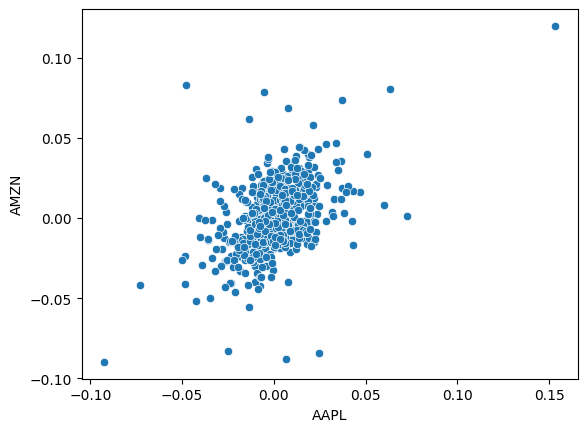

In [5]:
# Scatterplot
sns.scatterplot(data = returns, x = ticker1, y = ticker2)
plt.xlabel(ticker1)
plt.ylabel(ticker2)
plt.show()

### Cálculo covarianza

In [7]:
# Covarianza entre variables
df = pd.DataFrame({
    'Rend_Fondo': [0.05, 0.02, 0.03, 0.06, 0.01],
    'Rend_Mercado': [0.04,0.01, 0.02, 0.07, 0.00]
})


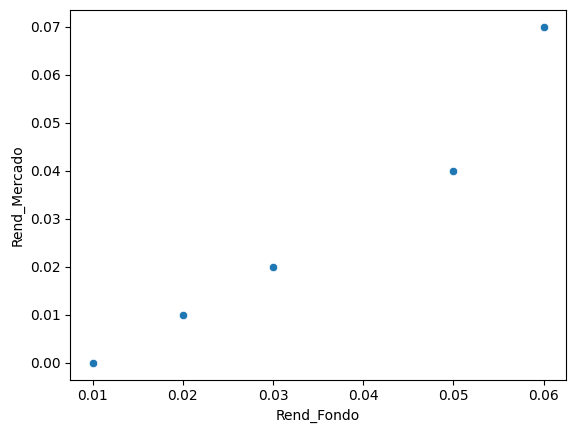

In [9]:
sns.scatterplot(data = df, x = 'Rend_Fondo', y = 'Rend_Mercado')
plt.show()


In [10]:
df.cov()

,Rend_Fondo,Rend_Mercado
Rend_Fondo,0.00043,0.00056
Rend_Mercado,0.00056,0.00077


### Covarianza depende de unidades! (correlación no)

In [12]:
import numpy as np

# Precios acciones USD
precios_usd = np.array([2.28, 3.5 , 2.91, 2.39, 2.49, 2.34, 2.02, 0.12, 2.2 , 2.78])

# Precios acciones EUR
precios_eur = precios_usd * 0.87

# Número de compradores
compradores = np.array([13, 13,  9, 13, 16, 14,  9, 19, 10, 15])

In [13]:
df_precios = pd.DataFrame({
    'precios_usd': precios_usd,
    'precios_eur': precios_eur,
    'compradores': compradores
})

,precios_usd,precios_eur,compradores
0,2.28,1.9836,13
1,3.50,3.0450,13
2,2.91,2.5317,9
3,2.39,2.0793,13
4,2.49,2.1663,16
5,2.34,2.0358,14
6,2.02,1.7574,9
7,0.12,0.1044,19
8,2.20,1.9140,10
9,2.78,2.4186,15


In [14]:
df_precios.cov()

,precios_usd,precios_eur,compradores
precios_usd,0.769934,0.669843,-1.392556
precios_eur,0.669843,0.582763,-1.211523
compradores,-1.392556,-1.211523,10.100000


In [15]:
df_precios.corr()

,precios_usd,precios_eur,compradores
precios_usd,1.000000,1.000000,-0.499373
precios_eur,1.000000,1.000000,-0.499373
compradores,-0.499373,-0.499373,1.000000


### Ejercicio 1: Felicidad vs Ingresos
* Plotea el diagrama de dispersión
* Calcula la covarianza y la correlación

In [16]:
ingresos = np.array([3808.89, 3000.66, 2060.25, 3697.99, 1726.67, 2874.89, 2225.02,
       3046.39, 3279.91, 2652.41,  826.79, 3668.09, 2818.06, 2699.47,
       2887.79, 1261.91, 3412.34, 3102.18, 2198.01, 1394.77, 1608.96,
       3454.45, 1791.88, 1183.04, 3054.35, 3027.99, 2770.24,  503.74,
       1001.95, 3245.91])

In [17]:
felicidad = np.array([9.67, 9.  , 8.59, 9.64, 8.21, 9.42, 8.5 , 9.47, 9.36, 9.48, 5.52,
       9.57, 9.64, 8.98, 9.63, 7.45, 9.37, 9.56, 8.64, 7.37, 7.96, 9.52,
       8.52, 6.72, 9.56, 9.87, 9.32, 4.15, 6.31, 9.38])

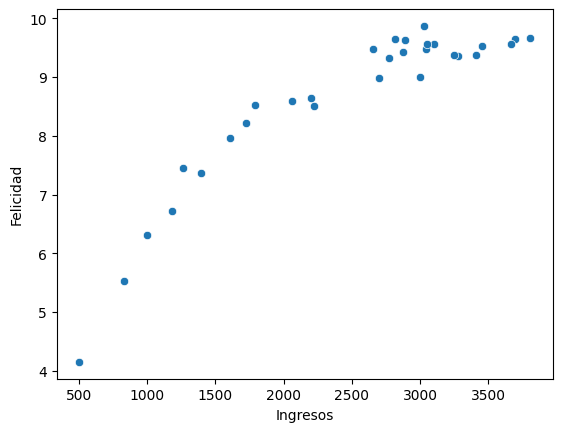

In [21]:
# Scatterplot
sns.scatterplot(x = ingresos, y = felicidad)
plt.xlabel('Ingresos')
plt.ylabel('Felicidad')
plt.show()

In [22]:
df = pd.DataFrame({
    'ingresos': ingresos,
    'felicidad': felicidad
})

In [25]:
# Covarianza
df.cov()

,ingresos,felicidad
ingresos,869000.719140,1176.449651
felicidad,1176.449651,1.927434


In [24]:
# Correlación
df.corr()

,ingresos,felicidad
ingresos,1.00000,0.90902
felicidad,0.90902,1.00000


### Ejercicio 2: Felicidad vs horas trabajadas

* Plotea el diagrama de dispersión
* Calcula la covarianza y la correlación

In [27]:
horas = np.array([ 0. ,  2.1,  4.1,  6.2,  8.3, 10.3, 12.4, 14.5, 16.6, 18.6, 20.7,
       22.8, 24.8, 26.9, 29. , 31. , 33.1, 35.2, 37.2, 39.3, 41.4, 43.4,
       45.5, 47.6, 49.7, 51.7, 53.8, 55.9, 57.9, 60. ])

In [28]:
felicidad = np.array([-9.06, -6.8 , -4.1 , -2.6 , -0.28,  1.27,  2.37,  4.18,  5.31,
        6.27,  7.05,  8.14,  8.97,  8.23,  8.91,  8.69,  8.38,  8.3 ,
        8.24,  7.15,  6.28,  5.15,  4.16,  3.12,  0.74, -0.49, -2.53,
       -4.09, -6.24, -8.72])

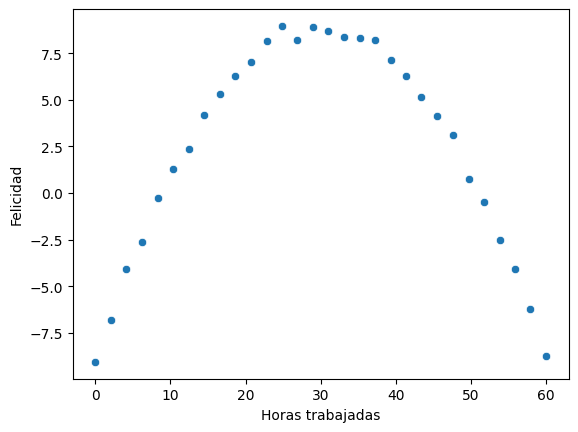

In [29]:
# Scatterplot
sns.scatterplot(x = horas, y = felicidad)
plt.xlabel('Horas trabajadas')
plt.ylabel('Felicidad')
plt.show()

In [31]:
df = pd.DataFrame({
    'horas': horas,
    'felicidad': felicidad
})

💡 **Insight**: Correlación 0 no implica independencia! (implica *ausencia de relación lineal*)

In [32]:
# Correlación
df.corr()

,horas,felicidad
horas,1.000000,0.007244
felicidad,0.007244,1.000000


### Regresión Lineal


#### Ejemplo RLS

Usa los retornos diarios del mercado y de un activo de interés `market_asset_returns.csv`
* Plotea los retornos con un diagrama de dispersión.
* ¿Parecen estar correlacionados? Calcula el coeficiente de correlación.
* Calcula el modelo de regresión, y úsalo para predecir el retorno del activo cuando el mercado tiene retornos de -1% y 2%.
* Plotea la recta de regresión junto a los datos.
* ¿Cuál es la beta? ¿Es un activo con más o menos riesgo que el mercado?

In [34]:
# Leer los datos
df = pd.read_csv('market_asset_returns.csv')

In [35]:
df.head()

,market_returns,asset_returns
0,0.0112,0.0260
1,0.0182,0.0150
2,-0.0062,0.0037
3,0.0237,0.0083
4,-0.0041,0.0223


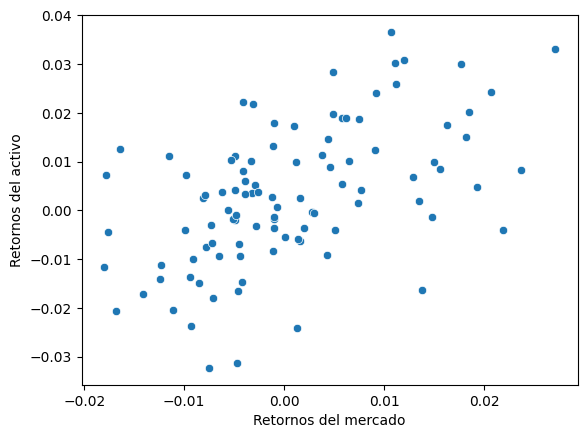

In [36]:
# Scatterplot
sns.scatterplot(data = df, x = 'market_returns', y = 'asset_returns')
plt.xlabel('Retornos del mercado')
plt.ylabel('Retornos del activo')
plt.show()

In [37]:
# Correlación
df.corr()

,market_returns,asset_returns
market_returns,1.000000,0.529536
asset_returns,0.529536,1.000000


In [41]:
# Calcula el modelo de regresión

from sklearn.linear_model import LinearRegression

# Formato necesario de variables para el modelo de regresión
X = df['market_returns'].values.reshape(-1, 1)
y = df['asset_returns']

# Create and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [44]:
# Extract the intercept (alpha) and coefficient (beta)
alpha = model.intercept_
beta = model.coef_[0]

In [45]:
alpha, beta

(np.float64(0.0025390935984673673), np.float64(0.758936571113747))

In [48]:
# Predecir el retorno del activo cuando el mercado tiene retornos de -1% y 2%
model.predict([[-0.01]]), model.predict([[0.02]])

(array([-0.00505027]), array([0.01771783]))

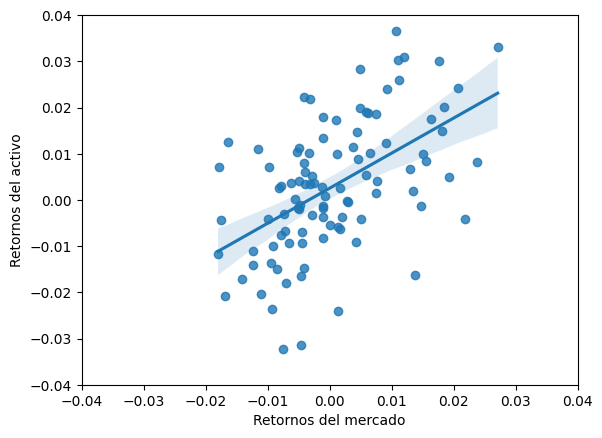

In [52]:
# Plotea la recta de regresión junto a los datos con los mismos límites en x e y
sns.regplot(data = df, x = 'market_returns', y = 'asset_returns')
plt.xlabel('Retornos del mercado')
plt.ylabel('Retornos del activo')

# Establecer los mismos límites para ambos ejes
plt.xlim(-0.04, 0.04)
plt.ylim(-0.04, 0.04)

plt.show()

#### 🧩 Ejercicio: relación entre una acción y el mercado
Utilizando los retornos diarios de los siguientes activos:
- QQQ: ETF que replica el Nasdaq-100.
- TSLA: Acción de Tesla.
Realiza las siguientes tareas:
1. Representa el diagrama de dispersión (scatterplot).
2. Calcula el coeficiente de correlación de Pearson.
3. Calcula la recta de regresión lineal, considerando QQQ como variable independiente y Tesla como variable dependiente.
4. Interpreta la pendiente de la recta (beta). ¿Es Tesla más o menos sensible que el mercado?
5. Representa la recta de regresión encima de los datos.
6. ¿Qué retorno estimado tendría Tesla cuando QQQ obtiene un retorno diario del 1%?

In [61]:
# Tickers a comparar
ticker1 = 'QQQ'
ticker2 = 'TSLA'

# Descargar datos
data = yf.download([ticker1, ticker2], start='2023-01-01', end='2025-10-26')['Close']

# Calcular rendibilidades diarias
returns = data.pct_change().dropna()

/tmp/ipykernel_633/1535232787.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download([ticker1, ticker2], start='2023-01-01', end='2025-10-26')['Close']
[*********************100%***********************]  2 of 2 completed


In [62]:
returns.head()

Ticker,QQQ,TSLA
Date,,
2023-01-04,0.004764,0.051249
2023-01-05,-0.015654,-0.029039
2023-01-06,0.027601,0.024651
2023-01-09,0.006473,0.059349
2023-01-10,0.008464,-0.007681


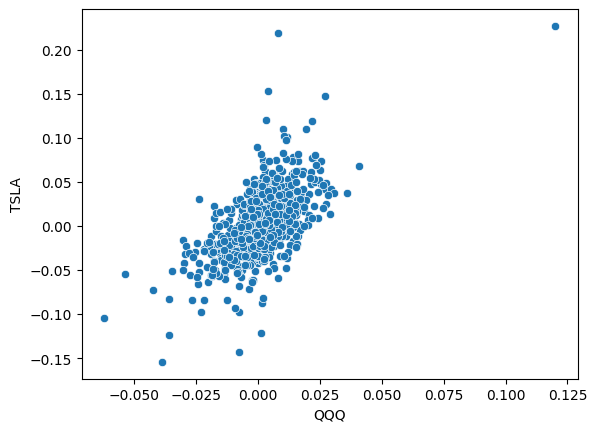

In [63]:
# Representa el diagrama de dispersión (scatterplot)
sns.scatterplot(data = returns, x = ticker1, y = ticker2)
plt.xlabel(ticker1)
plt.ylabel(ticker2)
plt.show()

In [64]:
# Calcula el coeficiente de correlación de Pearson.
returns.corr()

Ticker,QQQ,TSLA
Ticker,,
QQQ,1.000000,0.614358
TSLA,0.614358,1.000000


In [67]:
# Calcula la recta de regresión lineal
from sklearn.linear_model import LinearRegression

# Formato necesario de variables para el modelo de regresión
X = returns[ticker1].values.reshape(-1, 1)
y = returns[ticker2]

# Create and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Extract the intercept (alpha) and coefficient (beta)
alpha = model.intercept_
beta = model.coef_[0]

In [68]:
alpha, beta

(np.float64(0.00027274451813165445), np.float64(1.8572642747967942))

In [ ]:
# Interpreta la pendiente de la recta (beta): amplifica los movimientos del mercado!

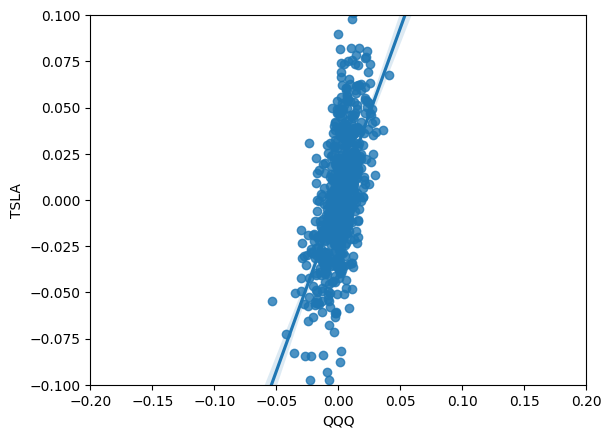

In [71]:
# Representa la recta de regresión encima de los datos.
sns.regplot(data = returns, x = ticker1, y = ticker2)
plt.xlabel(ticker1)
plt.ylabel(ticker2)
plt.xlim(-0.2,0.2)
plt.ylim(-0.1,0.1)
plt.show()

In [70]:
# ¿Qué retorno estimado tendría Tesla cuando QQQ obtiene un retorno diario del 1%?
model.predict([[0.01]])

array([0.01884539])